# Case A · Customer churn classification

## CRISP-DM question

Which customers should receive a limited retention offer?

The target is whether a customer churns in the next 30 days. Accuracy alone is
not enough: the campaign budget limits how many customers can be contacted.

**Learning objective:** compare a transparent baseline with a small tree model
and explain why the decision threshold changes the result.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from tutorial.data import write_datasets

paths = write_datasets(ROOT / "data")
ROOT

WindowsPath('C:/Users/Xie Yulong/Documents/ChatGPT/面试/data-science-crisp-dm-tutorial')

In [2]:
df = pd.read_csv(paths["churn"])
df.head()

,tenure_months,monthly_charge,support_calls,usage_hours,contract,autopay,region,churned
0,7,96.959000,3,15.037224,One year,Yes,East,1
1,56,66.949653,4,36.062132,Two year,Yes,West,0
2,48,79.269087,2,13.763179,Month-to-month,No,West,1
3,32,23.801561,1,16.196846,Month-to-month,Yes,North,0
4,32,48.873047,0,26.560274,One year,Yes,East,0


In [3]:
print(df.info())
print("\nMissing share:")
print(df.isna().mean().sort_values(ascending=False))
print("\nTarget distribution:")
print(df["churned"].value_counts(normalize=True).rename("share"))

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   tenure_months   1200 non-null   int64  
 1   monthly_charge  1182 non-null   float64
 2   support_calls   1200 non-null   int64  
 3   usage_hours     1200 non-null   float64
 4   contract        1200 non-null   str    
 5   autopay         1191 non-null   str    
 6   region          1200 non-null   str    
 7   churned         1200 non-null   int64  
dtypes: float64(2), int64(3), str(3)
memory usage: 96.6 KB
None

Missing share:
monthly_charge    0.0150
autopay           0.0075
support_calls     0.0000
tenure_months     0.0000
usage_hours       0.0000
contract          0.0000
region            0.0000
churned           0.0000
dtype: float64

Target distribution:
churned
0    0.578333
1    0.421667
Name: share, dtype: float64


## Fit the two candidate models

The reusable implementation uses one train/test split, a preprocessing
pipeline and a threshold of 0.40. This avoids fitting transformations on the
test set.


In [4]:
from tutorial.examples import run_churn_example

churn = run_churn_example()

pd.DataFrame({
    "logistic regression": churn.logistic_metrics,
    "decision tree": churn.tree_metrics,
}).T

,accuracy,precision,recall,f1,roc_auc
logistic regression,0.7133,0.6282,0.7778,0.6950,0.7707
decision tree,0.6233,0.5414,0.6746,0.6007,0.6761


In [5]:
pd.Series(churn.confusion, name="customers").to_frame()

,customers
true_negative,116
false_positive,58
false_negative,28
true_positive,98


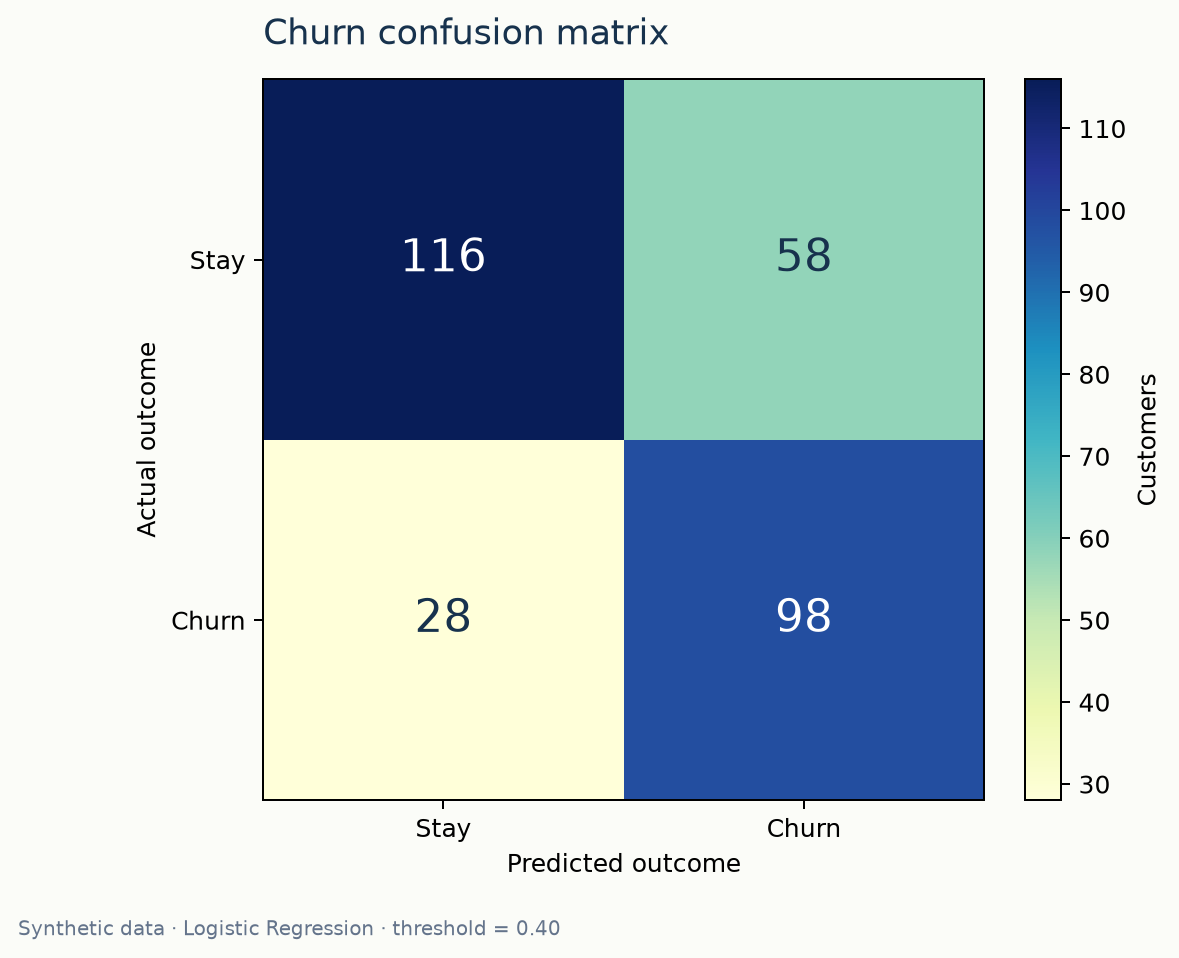

In [6]:
display(Image(filename=str(ROOT / "assets" / "img" / "churn-confusion.png")))

## Interpretation and exercise

1. Which model has higher Recall at the selected threshold?
2. What happens if you lower the threshold from 0.40 to 0.30?
3. Which error is more expensive for the business: a missed churner or an
   unnecessary retention offer?

The synthetic relationship is only a teaching device. It is not evidence about
real customers.
